# 01 · Data exploration — Lung nodule/mass detection on chest X-rays

**Goal of the project:** train a CNN that flags chest X-rays showing a **lung nodule or mass** versus a **normal** X-ray ("No Finding"), and report AUC-ROC and sensitivity on a held-out test set.

**This notebook:**
1. Downloads part of the NIH ChestX-ray14 dataset
2. Explores the labels
3. Builds the binary task (Nodule/Mass vs No Finding)
4. Splits the data **by patient** into train / validation / test, so the same patient never appears in two splits (avoids data leakage)
5. Saves the splits for `02_train.ipynb`

**Data:** NIH ChestX-ray14 (Wang et al., CVPR 2017), 112,120 frontal X-rays from 30,805 patients. Research use only; not for clinical use.

## 1. Configuration

In [1]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repo root
DATA_DIR = ROOT / "data"          # everything downloaded goes here (git-ignored)
IMAGE_DIR = DATA_DIR / "images"
SPLIT_DIR = DATA_DIR / "splits"

PARTS = list(range(1, 13))   # which of the 12 image archives to download (~4 GB each). 1–3 ≈ 25k images
NEG_PER_POS = 3     # how many normal X-rays to keep for each positive one
SEED = 42

DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)
SPLIT_DIR.mkdir(exist_ok=True)

## 2. Check the Mac GPU (MPS)

In [2]:
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


## 3. Download the data

Downloads the label file and the selected image archives from the official NIH source, then extracts them. Already-downloaded parts are skipped, so this cell is safe to re-run. Expect roughly 4 GB and a few minutes per part.

In [4]:
import tarfile
import urllib.request

LABELS_URL = ("https://nihcc.app.box.com/index.php?rm=box_download_shared_file"
              "&vanity_name=ChestXray-NIHCC&file_id=f_219760887468")
PART_URLS = [
    "https://nihcc.box.com/shared/static/vfk49d74nhbxq3nqjg0900w5nvkorp5c.gz",
    "https://nihcc.box.com/shared/static/i28rlmbvmfjbl8p2n3ril0pptcmcu9d1.gz",
    "https://nihcc.box.com/shared/static/f1t00wrtdk94satdfb9olcolqx20z2jp.gz",
    "https://nihcc.box.com/shared/static/0aowwzs5lhjrceb3qp67ahp0rd1l1etg.gz",
    "https://nihcc.box.com/shared/static/v5e3goj22zr6h8tzualxfsqlqaygfbsn.gz",
    "https://nihcc.box.com/shared/static/asi7ikud9jwnkrnkj99jnpfkjdes7l6l.gz",
    "https://nihcc.box.com/shared/static/jn1b4mw4n6lnh74ovmcjb8y48h8xj07n.gz",
    "https://nihcc.box.com/shared/static/tvpxmn7qyrgl0w8wfh9kqfjskv6nmm1j.gz",
    "https://nihcc.box.com/shared/static/upyy3ml7qdumlgk2rfcvlb9k6gvqq2pj.gz",
    "https://nihcc.box.com/shared/static/l6nilvfa9cg3s28tqv1qc1olm3gnz54p.gz",
    "https://nihcc.box.com/shared/static/hhq8fkdgvcari67vfhs7ppg2w6ni4jze.gz",
    "https://nihcc.box.com/shared/static/ioqwiy20ihqwyr8pf4c24eazhh281pbu.gz",
]

LABELS_CSV = DATA_DIR / "Data_Entry_2017.csv"


def download(url, dest):
    def progress(blocks, block_size, total):
        if total > 0:
            pct = min(100, blocks * block_size * 100 // total)
            print(f"\r  {dest.name}: {pct}%", end="")
    urllib.request.urlretrieve(url, dest, reporthook=progress)
    print()


if not LABELS_CSV.exists():
    print("Downloading labels...")
    download(LABELS_URL, LABELS_CSV)

for part in PARTS:
    done_marker = DATA_DIR / f".part{part:02d}.done"
    if done_marker.exists():
        print(f"Part {part:02d} already extracted, skipping")
        continue
    archive = DATA_DIR / f"images_{part:02d}.tar.gz"
    print(f"Downloading part {part:02d}...")
    download(PART_URLS[part - 1], archive)
    print(f"Extracting part {part:02d}...")
    with tarfile.open(archive) as tar:  # archives contain an images/ folder
        try:
            tar.extractall(DATA_DIR, filter="data")   # safe extraction (Python 3.12+)
        except TypeError:
            tar.extractall(DATA_DIR)
    archive.unlink()                  # free disk space
    done_marker.touch()

print("Images on disk:", sum(1 for _ in IMAGE_DIR.glob("*.png")))

Part 01 already extracted, skipping
Part 02 already extracted, skipping
Part 03 already extracted, skipping
Part 04 already extracted, skipping
Part 05 already extracted, skipping
Part 06 already extracted, skipping
Part 07 already extracted, skipping
Part 08 already extracted, skipping
  images_09.tar.gz: 100%
Extracting part 09...
  images_10.tar.gz: 100%
Extracting part 10...
  images_11.tar.gz: 100%
Extracting part 11...
  images_12.tar.gz: 100%
Extracting part 12...
Images on disk: 112120


## 4. Load the labels and keep only the images we downloaded

In [5]:
import pandas as pd

df = pd.read_csv(LABELS_CSV)
print("Rows in full label file:", len(df))

on_disk = {p.name for p in IMAGE_DIR.glob("*.png")}
df = df[df["Image Index"].isin(on_disk)].reset_index(drop=True)
print("Rows with an image on disk:", len(df))
print("Patients:", df["Patient ID"].nunique())
df.head()

Rows in full label file: 112120
Rows with an image on disk: 112120
Patients: 30805


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


## 5. Label distribution

`Finding Labels` holds one or more findings separated by `|` (e.g. `Nodule|Effusion`). Most X-rays are `No Finding`, so the data is heavily imbalanced; this matters for which metric we report later (AUC and sensitivity, not plain accuracy).

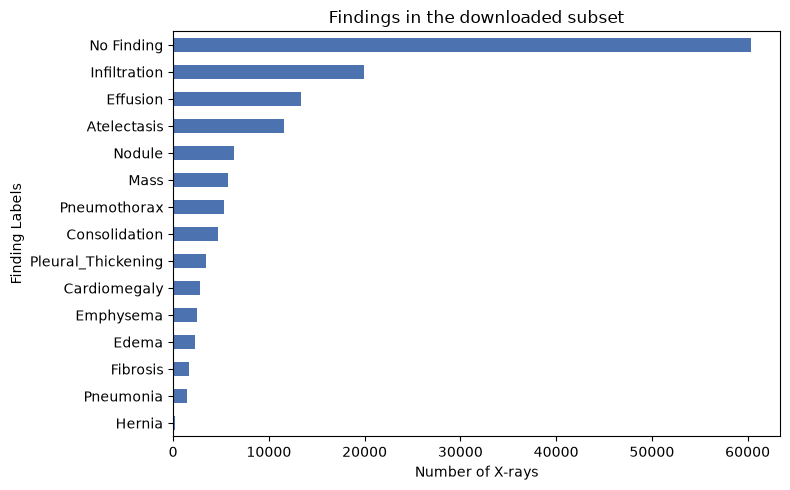

Finding Labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64

In [6]:
import matplotlib.pyplot as plt

label_counts = df["Finding Labels"].str.split("|").explode().value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
label_counts.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Number of X-rays")
ax.set_title("Findings in the downloaded subset")
plt.tight_layout()
plt.show()

label_counts

## 6. Build the binary task

- **Positive (1):** the X-ray lists `Nodule` or `Mass` (it may also list other findings)
- **Negative (0):** the X-ray is `No Finding`
- X-rays with other findings only are dropped, so the model learns nodule/mass versus normal rather than versus other diseases.

We keep every positive and randomly sample `NEG_PER_POS` negatives per positive (fixed seed, so the cohort is reproducible).

In [7]:
findings = df["Finding Labels"].str.split("|")
is_pos = findings.apply(lambda f: "Nodule" in f or "Mass" in f)
is_neg = df["Finding Labels"] == "No Finding"

pos = df[is_pos].assign(label=1)
neg = df[is_neg].assign(label=0)
n_neg = min(len(neg), NEG_PER_POS * len(pos))
neg = neg.sample(n=n_neg, random_state=SEED)

cohort = pd.concat([pos, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
cohort = cohort[["Image Index", "Patient ID", "Patient Age", "View Position", "Finding Labels", "label"]]

print(f"Positives: {len(pos)} | Negatives kept: {len(neg)} | Total: {len(cohort)}")
print(f"Positive rate: {cohort['label'].mean():.1%}")

Positives: 11207 | Negatives kept: 33621 | Total: 44828
Positive rate: 25.0%


## 7. Split by patient (70 / 15 / 15)

One patient can have many X-rays. A random split by image would put the same patient in both train and test, and the model could score well by recognising the patient instead of the disease. Splitting by `Patient ID` prevents that.

In [8]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, rest_idx = next(gss.split(cohort, groups=cohort["Patient ID"]))
train, rest = cohort.iloc[train_idx], cohort.iloc[rest_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(rest, groups=rest["Patient ID"]))
val, test = rest.iloc[val_idx], rest.iloc[test_idx]

# Leakage check: no patient appears in two splits
p_train, p_val, p_test = (set(s["Patient ID"]) for s in (train, val, test))
assert not (p_train & p_val) and not (p_train & p_test) and not (p_val & p_test)

summary = pd.DataFrame({
    "images": [len(train), len(val), len(test)],
    "patients": [len(p_train), len(p_val), len(p_test)],
    "positive_rate": [s["label"].mean() for s in (train, val, test)],
}, index=["train", "val", "test"])
summary.style.format({"positive_rate": "{:.1%}"})

,images,patients,positive_rate
train,31055,13608,25.2%
val,6807,2916,23.8%
test,6966,2917,25.4%


## 8. Look at some examples

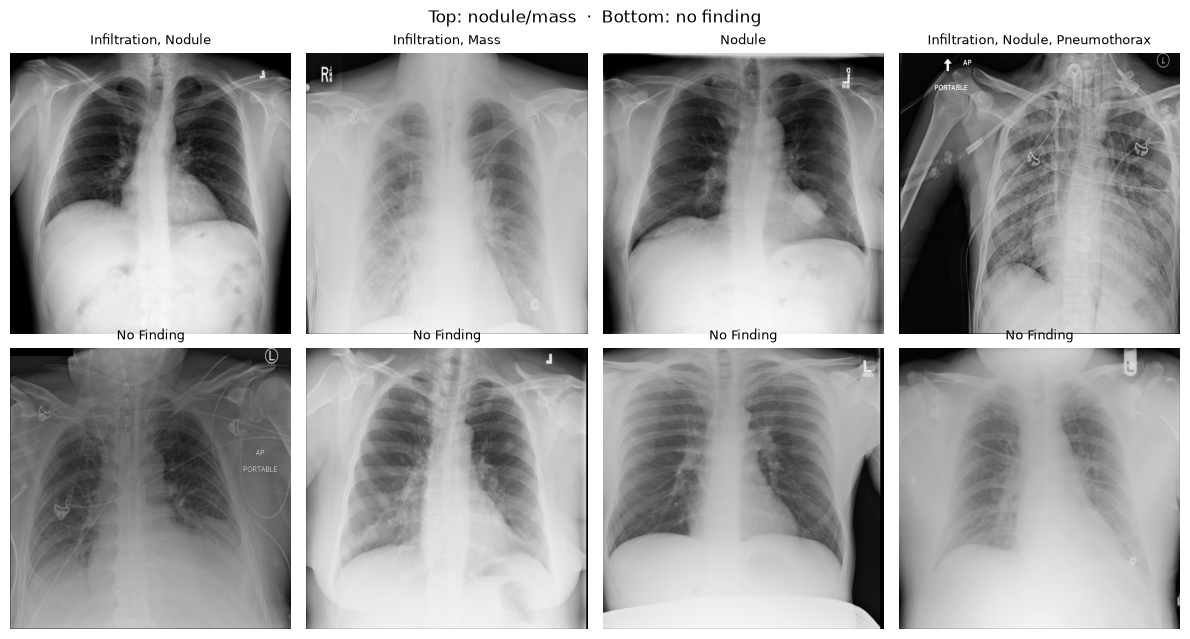

Image size: (1024, 1024) | mode of original: L


In [9]:
from PIL import Image

examples = pd.concat([
    cohort[cohort["label"] == 1].sample(4, random_state=SEED),
    cohort[cohort["label"] == 0].sample(4, random_state=SEED),
])

fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    img = Image.open(IMAGE_DIR / row["Image Index"]).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(row["Finding Labels"].replace("|", ", "), fontsize=9)
    ax.axis("off")
fig.suptitle("Top: nodule/mass  ·  Bottom: no finding")
plt.tight_layout()
plt.show()

print("Image size:", img.size, "| mode of original:", Image.open(IMAGE_DIR / row["Image Index"]).mode)

## 9. Save the splits for training

In [10]:
for name, split in [("train", train), ("val", val), ("test", test)]:
    split.to_csv(SPLIT_DIR / f"{name}.csv", index=False)
    print(f"Saved {SPLIT_DIR / f'{name}.csv'}  ({len(split)} images)")

Saved /Users/TrungVu/code/chest_xray_classifier/data/splits/train.csv  (31055 images)
Saved /Users/TrungVu/code/chest_xray_classifier/data/splits/val.csv  (6807 images)
Saved /Users/TrungVu/code/chest_xray_classifier/data/splits/test.csv  (6966 images)


## Summary

- Built a binary cohort (nodule/mass vs no finding) from the downloaded NIH ChestX-ray14 subset.
- Split **by patient** into train / validation / test, with a check that no patient leaks across splits.
- Saved the splits to `data/splits/`.

**Next:** `02_train.ipynb` fine-tunes a pretrained CNN (ResNet / DenseNet) on these splits using the Mac GPU (MPS).